# Practical Assignment 1 — Part I: CNN Classification on CIFAR-10

## Objective

The objective of Part I is to design, implement, train, and evaluate a Convolutional Neural Network (CNN) on the CIFAR-10 dataset.

The CNN must achieve a mean-Class Accuracy (mCA) of at least 85%, using no more than six convolutional layers.

Four different hyperparameter configurations will be evaluated and compared using classification metrics, loss curves, and a confusion matrix.


In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)


PyTorch version: 2.14.1
Torchvision version: 0.29.1


In [2]:
SEED = 42 #Para tornar as experiências mais reprodutíveis.Por exemplo, queremos que os quatro modelos sejam avaliados com a mesma divisão treino/validação. A seed ajuda a garantir isso, embora não assegure resultados totalmente idênticos em todos os dispositivos.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


### etapa2
Carregar e preparar o CIFAR-10

In [3]:
# ==========================================
# 3. Data Transformations
# ==========================================

# CIFAR-10 normalization values
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


descarregar o cifar

In [4]:

# ==========================================
# 4. Load CIFAR-10 Dataset
# ==========================================

# Dataset with training augmentation
training_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Same original images, without augmentation
validation_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

# Official test dataset
testing_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

class_names = training_data.classes

print("Training dataset:", len(training_data))
print("Testing dataset:", len(testing_data))
print("Classes:", class_names)


Training dataset: 50000
Testing dataset: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [5]:
# ==========================================
# 5. Training / Validation Split
# ==========================================

num_train = len(training_data)

indices = np.arange(num_train)

rng = np.random.default_rng(SEED)
rng.shuffle(indices)

split = int(num_train * 0.2)

valid_idx = indices[:split]
training_idx = indices[split:]

train_set = Subset(
    training_data,
    training_idx.tolist()
)

val_set = Subset(
    validation_data,
    valid_idx.tolist()
)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Testing images:", len(testing_data))


Training images: 40000
Validation images: 10000
Testing images: 10000


In [6]:
# ==========================================
# 6. DataLoaders
# ==========================================

batch_size = 128

training_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

testing_loader = DataLoader(
    testing_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(training_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(testing_loader))


Training batches: 313
Validation batches: 79
Testing batches: 79


### etapa 3

Visualizar as imagens

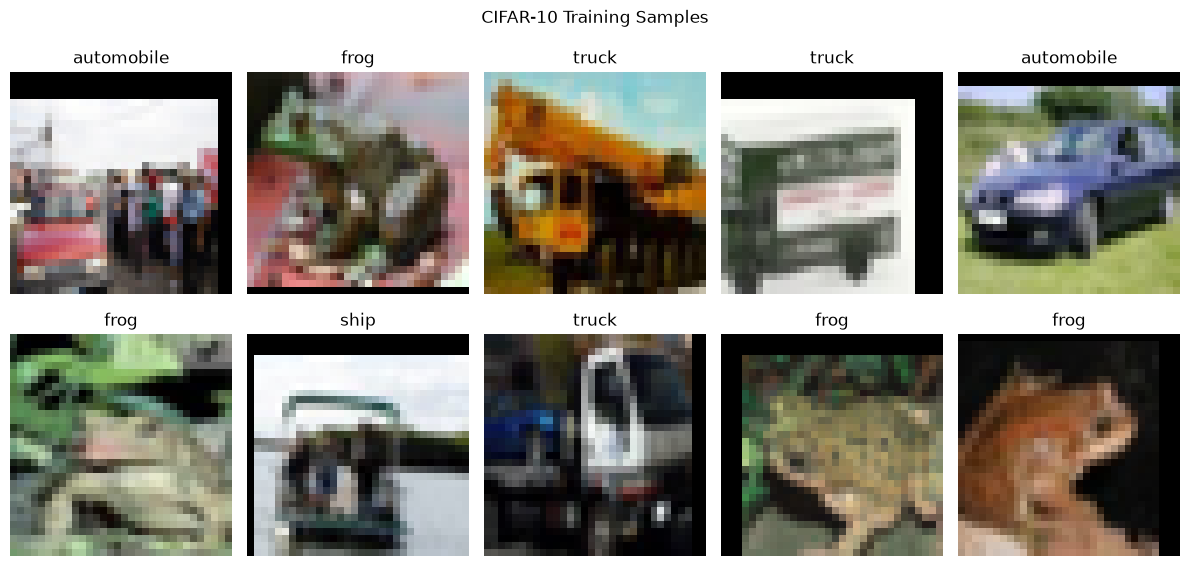

In [7]:
# ==========================================
# 7. Visualize CIFAR-10 Images
# ==========================================

images, labels = next(iter(training_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

for i, ax in enumerate(axes.flat):

    image = images[i].cpu()

    # Undo normalization
    image = image * std_tensor + mean_tensor
    image = image.clamp(0, 1)

    # Convert CHW to HWC
    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Training Samples")
plt.tight_layout()
plt.show()


In [8]:

# ==========================================
# 8. Verify Dataset Dimensions
# ==========================================

images, labels = next(iter(training_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)


Images shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Image data type: torch.float32


## CNN Architecture

A custom CNN architecture is implemented with six convolutional layers organized into three convolutional blocks.

Each block includes Batch Normalization, ReLU activation functions, and MaxPooling.

The classification head consists of two fully connected layers and Dropout regularization.

The architecture respects the maximum of six convolutional layers required by the assignment.


In [9]:
# ==========================================
# 9. CNN Architecture
# ==========================================

class CNNModel(nn.Module):

    def __init__(self, number_of_classes=10, dropout=0.3):
        super(CNNModel, self).__init__()

        # Convolutional Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Convolutional Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Convolutional Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Classification Head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(256, number_of_classes)
        )

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.classifier(x)

        return x


In [10]:
# ==========================================
# 10. Initialize CNN
# ==========================================

cnn_model = CNNModel(
    number_of_classes=10,
    dropout=0.3
).to(device)

print("CNN Architecture:")
print(cnn_model)

print("\nDevice:", device)


CNN Architecture:
CNNModel(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, c

In [11]:
# ==========================================
# 11. Model Parameters
# ==========================================

total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in cnn_model.parameters()
    if p.requires_grad
)

conv_layers = sum(
    1 for module in cnn_model.modules()
    if isinstance(module, nn.Conv2d)
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Convolutional layers: {conv_layers}")


Total parameters: 2,198,602
Trainable parameters: 2,198,602
Convolutional layers: 6


In [12]:
# ==========================================
# 12. Test Forward Pass
# ==========================================

cnn_model.eval()

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(training_loader)
    )

    sample_images = sample_images[:8].to(device)

    outputs = cnn_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)


Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 10])


In [13]:
# ==========================================
# 13. Inspect Feature Dimensions
# ==========================================

cnn_model.eval()

with torch.no_grad():

    x = sample_images

    print("Input:", x.shape)

    x = cnn_model.block1(x)
    print("After Block 1:", x.shape)

    x = cnn_model.block2(x)
    print("After Block 2:", x.shape)

    x = cnn_model.block3(x)
    print("After Block 3:", x.shape)

    x = cnn_model.classifier(x)
    print("After Classifier:", x.shape)


Input: torch.Size([8, 3, 32, 32])
After Block 1: torch.Size([8, 64, 16, 16])
After Block 2: torch.Size([8, 128, 8, 8])
After Block 3: torch.Size([8, 256, 4, 4])
After Classifier: torch.Size([8, 10])


## CNN Training and Validation

The CNN is trained using CrossEntropyLoss and the AdamW optimizer.

A cosine annealing learning rate scheduler is used to progressively adjust the learning rate during training.

At each epoch, training loss, validation loss, and validation mean-Class Accuracy (mCA) are recorded.

The model weights corresponding to the highest validation mCA are saved for subsequent evaluation.


In [14]:
# ==========================================
# 14. Training and Validation Function
# ==========================================

import copy
import time

def train_model(
    model,
    train_loader,
    val_loader,
    lr=0.001,
    epochs=30,
    weight_decay=0.0001,
    model_name="cnn"
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_mca": [],
        "learning_rate": []
    }

    best_val_mca = -1.0
    best_epoch = 0
    best_model_weights = copy.deepcopy(model.state_dict())

    os.makedirs("models", exist_ok=True)

    for epoch in range(epochs):

        start_time = time.time()

        # ==================================
        # TRAINING
        # ==================================

        model.train()

        running_train_loss = 0.0
        train_samples = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_train_loss += (
                loss.item() * images.size(0)
            )

            train_samples += images.size(0)

        avg_train_loss = (
            running_train_loss / train_samples
        )

        # ==================================
        # VALIDATION
        # ==================================

        model.eval()

        running_val_loss = 0.0
        val_samples = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += (
                    loss.item() * images.size(0)
                )

                val_samples += images.size(0)

                predictions = torch.argmax(
                    outputs, dim=1
                )

                all_labels.extend(
                    labels.cpu().numpy()
                )

                all_predictions.extend(
                    predictions.cpu().numpy()
                )

        avg_val_loss = (
            running_val_loss / val_samples
        )

        val_mca = recall_score(
            all_labels,
            all_predictions,
            labels=list(range(10)),
            average="macro",
            zero_division=0
        )

        current_lr = optimizer.param_groups[0]["lr"]

        # ==================================
        # SAVE HISTORY
        # ==================================

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_mca"].append(val_mca)
        history["learning_rate"].append(current_lr)

        # ==================================
        # SAVE BEST MODEL
        # ==================================

        if val_mca > best_val_mca:

            best_val_mca = val_mca
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_model_weights,
                f"models/{model_name}_best.pth"
            )

        scheduler.step()

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Val mCA: {val_mca*100:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

    model.load_state_dict(best_model_weights)

    print("\nTraining completed!")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation mCA: {best_val_mca*100:.2f}%")

    return model, history


In [15]:
# ==========================================
# 15. Training Pipeline Test
# ==========================================

test_model = CNNModel(
    number_of_classes=10,
    dropout=0.3
).to(device)

test_model, test_history = train_model(
    model=test_model,
    train_loader=training_loader,
    val_loader=valid_loader,
    lr=0.001,
    epochs=2,
    weight_decay=0.0001,
    model_name="cnn_test"
)


Epoch [1/2] | Train Loss: 1.6411 | Val Loss: 1.2663 | Val mCA: 53.08% | Time: 59.7s
Epoch [2/2] | Train Loss: 1.1679 | Val Loss: 1.0750 | Val mCA: 62.38% | Time: 59.6s

Training completed!
Best epoch: 2
Best validation mCA: 62.38%


In [16]:
# ==========================================
# 16. Check Training History
# ==========================================

print("Training losses:", test_history["train_loss"])
print("Validation losses:", test_history["val_loss"])
print("Validation mCA:", test_history["val_mca"])

print(
    "\nBest validation mCA:",
    f"{max(test_history['val_mca'])*100:.2f}%"
)

print(
    "Model saved:",
    os.path.exists("models/cnn_test_best.pth")
)


Training losses: [1.641055581665039, 1.167869214439392]
Validation losses: [1.2662680284500123, 1.075026905822754]
Validation mCA: [0.5308293395533773, 0.6238475612796216]

Best validation mCA: 62.38%
Model saved: True


In [17]:
# ==========================================
# 17. Plot Training Curves
# ==========================================

def plot_training_curves(history, title="CNN Training"):

    epochs_range = range(
        1,
        len(history["train_loss"]) + 1
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5)
    )

    # Loss curves
    axes[0].plot(
        epochs_range,
        history["train_loss"],
        label="Training Loss",
        marker="o"
    )

    axes[0].plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss",
        marker="o"
    )

    axes[0].set_title("Training vs Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("CrossEntropy Loss")
    axes[0].legend()
    axes[0].grid(True)

    # Validation mCA
    axes[1].plot(
        epochs_range,
        np.array(history["val_mca"]) * 100,
        label="Validation mCA",
        marker="o"
    )

    axes[1].axhline(
        y=85,
        linestyle="--",
        label="Target: 85%"
    )

    axes[1].set_title("Validation Mean-Class Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("mCA (%)")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


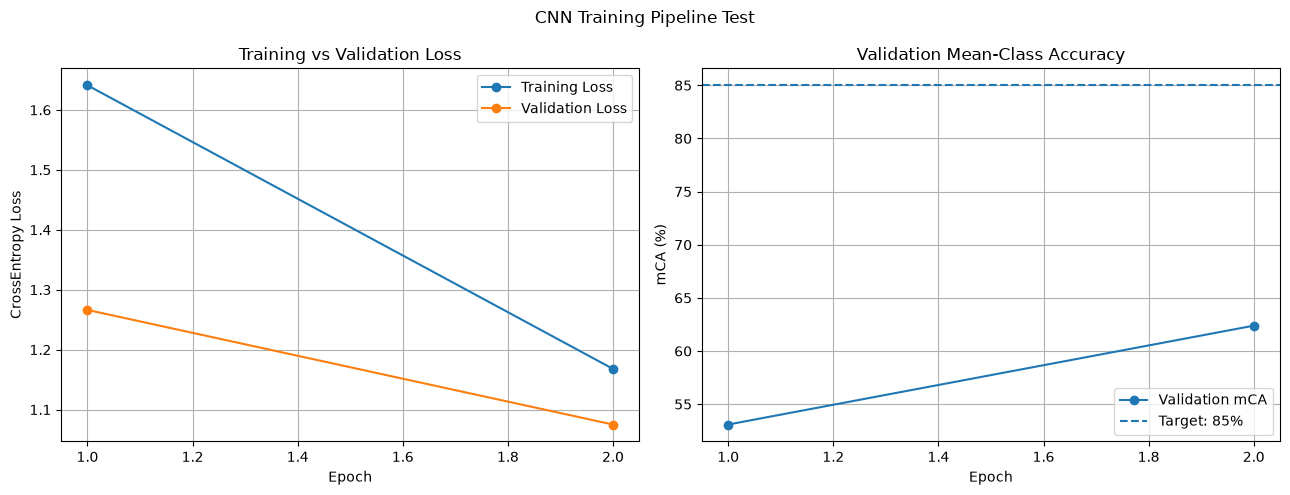

In [18]:
# ==========================================
# 18. Visualize Test Training
# ==========================================

plot_training_curves(
    test_history,
    title="CNN Training Pipeline Test"
)


In [19]:
# ==========================================
# 19. Hyperparameter Experiment Configurations
# ==========================================

experiments = [
    {
        "name": "EXP1_baseline",
        "lr": 0.001,
        "batch_size": 128,
        "dropout": 0.3
    },
    {
        "name": "EXP2_lr_0005",
        "lr": 0.0005,
        "batch_size": 128,
        "dropout": 0.3
    },
    {
        "name": "EXP3_batch_64",
        "lr": 0.001,
        "batch_size": 64,
        "dropout": 0.3
    },
    {
        "name": "EXP4_dropout_05",
        "lr": 0.001,
        "batch_size": 128,
        "dropout": 0.5
    }
]

EPOCHS = 20

for exp in experiments:
    print(
        f"{exp['name']}: "
        f"lr={exp['lr']}, "
        f"batch_size={exp['batch_size']}, "
        f"dropout={exp['dropout']}"
    )

print(f"\nEpochs per experiment: {EPOCHS}")
print(f"Total planned epochs: {len(experiments) * EPOCHS}")


EXP1_baseline: lr=0.001, batch_size=128, dropout=0.3
EXP2_lr_0005: lr=0.0005, batch_size=128, dropout=0.3
EXP3_batch_64: lr=0.001, batch_size=64, dropout=0.3
EXP4_dropout_05: lr=0.001, batch_size=128, dropout=0.5

Epochs per experiment: 20
Total planned epochs: 80


In [20]:
# ==========================================
# 20. Create DataLoaders for Each Experiment
# ==========================================

def create_loaders(batch_size):

    train_loader = DataLoader(
        train_set,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    validation_loader = DataLoader(
        val_set,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, validation_loader


for exp in experiments:

    train_loader, validation_loader = create_loaders(
        exp["batch_size"]
    )

    print(
        f"{exp['name']}: "
        f"{len(train_loader)} training batches, "
        f"{len(validation_loader)} validation batches"
    )


EXP1_baseline: 313 training batches, 79 validation batches
EXP2_lr_0005: 313 training batches, 79 validation batches
EXP3_batch_64: 625 training batches, 157 validation batches
EXP4_dropout_05: 313 training batches, 79 validation batches


In [21]:
# ==========================================
# 21. Run All Four Experiments
# ==========================================

all_histories = {}
experiment_results = []

for exp in experiments:

    print("\n" + "=" * 65)
    print(f"Starting {exp['name']}")
    print("=" * 65)

    # Create a fresh model for this experiment
    model = CNNModel(
        number_of_classes=10,
        dropout=exp["dropout"]
    ).to(device)

    # Create loaders using the selected batch size
    train_loader, validation_loader = create_loaders(
        exp["batch_size"]
    )

    # Train the model
    model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=validation_loader,
        lr=exp["lr"],
        epochs=EPOCHS,
        weight_decay=0.0001,
        model_name=exp["name"]
    )

    # Save training history in memory
    all_histories[exp["name"]] = history

    # Record experiment results
    best_epoch_idx = int(np.argmax(history["val_mca"]))

    experiment_results.append({
        "Experiment": exp["name"],
        "Learning Rate": exp["lr"],
        "Batch Size": exp["batch_size"],
        "Dropout": exp["dropout"],
        "Best Epoch": best_epoch_idx + 1,
        "Best Val mCA (%)": (
            history["val_mca"][best_epoch_idx] * 100
        ),
        "Train Loss": history["train_loss"][best_epoch_idx],
        "Val Loss": history["val_loss"][best_epoch_idx]
    })

    # Release references before the next experiment
    del model
    if device.type == "mps":
        torch.mps.empty_cache()
    elif device.type == "cuda":
        torch.cuda.empty_cache()

print("\nAll experiments completed!")



Starting EXP1_baseline
Epoch [1/20] | Train Loss: 1.7112 | Val Loss: 1.3944 | Val mCA: 48.39% | Time: 59.5s
Epoch [2/20] | Train Loss: 1.2681 | Val Loss: 1.1200 | Val mCA: 60.14% | Time: 58.8s
Epoch [3/20] | Train Loss: 1.0614 | Val Loss: 0.8917 | Val mCA: 67.76% | Time: 59.7s
Epoch [4/20] | Train Loss: 0.9271 | Val Loss: 0.9632 | Val mCA: 67.17% | Time: 58.7s
Epoch [5/20] | Train Loss: 0.8235 | Val Loss: 0.8278 | Val mCA: 71.32% | Time: 64.1s
Epoch [6/20] | Train Loss: 0.7447 | Val Loss: 0.7251 | Val mCA: 74.52% | Time: 70.1s
Epoch [7/20] | Train Loss: 0.6812 | Val Loss: 0.7178 | Val mCA: 75.07% | Time: 70.1s
Epoch [8/20] | Train Loss: 0.6203 | Val Loss: 0.6352 | Val mCA: 77.57% | Time: 70.2s
Epoch [9/20] | Train Loss: 0.5697 | Val Loss: 0.5774 | Val mCA: 80.24% | Time: 72.0s
Epoch [10/20] | Train Loss: 0.5311 | Val Loss: 0.6104 | Val mCA: 79.81% | Time: 75.8s
Epoch [11/20] | Train Loss: 0.4876 | Val Loss: 0.4777 | Val mCA: 83.58% | Time: 75.7s
Epoch [12/20] | Train Loss: 0.4528 | Va

In [22]:
# ==========================================
# 22. Compare Experiment Results
# ==========================================

import pandas as pd

results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="Best Val mCA (%)",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Experiment,Learning Rate,Batch Size,Dropout,Best Epoch,Best Val mCA (%),Train Loss,Val Loss
0,EXP2_lr_0005,0.0005,128,0.3,19,88.7630,0.2451,0.3429
1,EXP3_batch_64,0.0010,64,0.3,19,88.3067,0.2795,0.3544
2,EXP1_baseline,0.0010,128,0.3,20,87.5931,0.2861,0.3726
3,EXP4_dropout_05,0.0010,128,0.5,20,87.3785,0.3187,0.3845


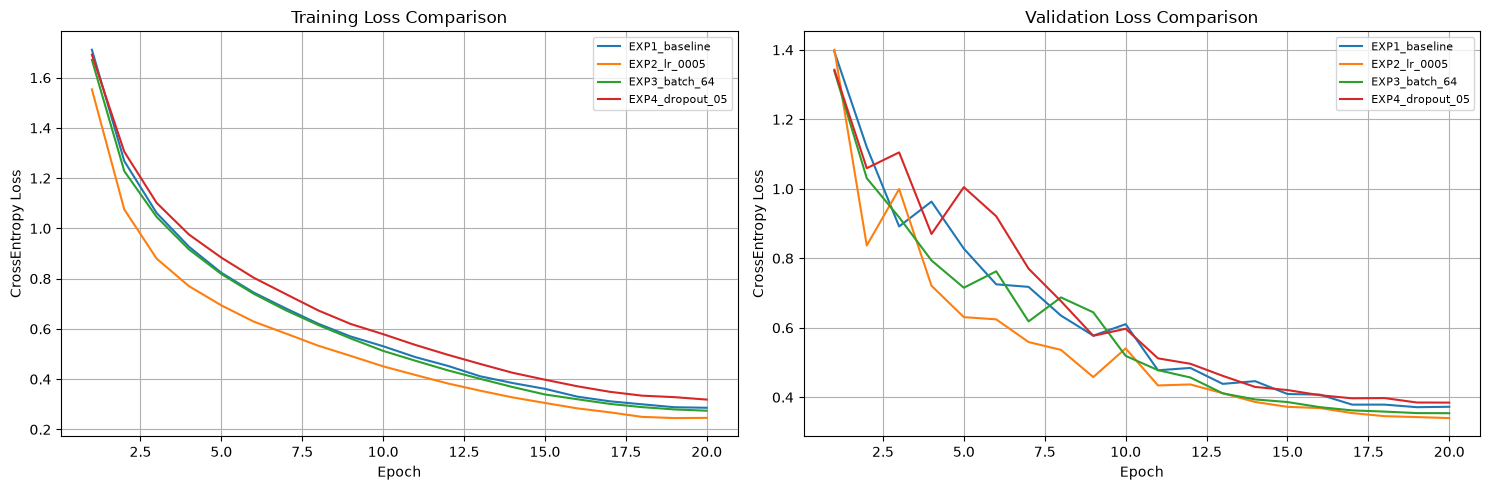

In [23]:
# ==========================================
# 23. Compare Training and Validation Losses
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in all_histories.items():

    epochs_range = range(
        1, len(history["train_loss"]) + 1
    )

    axes[0].plot(
        epochs_range,
        history["train_loss"],
        label=name
    )

    axes[1].plot(
        epochs_range,
        history["val_loss"],
        label=name
    )

axes[0].set_title("Training Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("CrossEntropy Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.show()


## Evaluation of the Best CNN Model on the Test Set

In [24]:
best_experiment = results_df.iloc[0]

best_model = CNNModel(
    number_of_classes=10,
    dropout=float(best_experiment["Dropout"])
).to(device)

checkpoint_path = f"models/{best_experiment['Experiment']}_best.pth"

best_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

best_model.eval()

print("Best experiment:", best_experiment["Experiment"])
print("Checkpoint:", checkpoint_path)
print("Validation mCA:", f"{best_experiment['Best Val mCA (%)']:.2f}%")

Best experiment: EXP2_lr_0005
Checkpoint: models/EXP2_lr_0005_best.pth
Validation mCA: 88.76%


In [25]:
all_test_labels = []
all_test_predictions = []

best_model.eval()

with torch.no_grad():
    for images, labels in testing_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_test_labels.extend(labels.numpy())
        all_test_predictions.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(
    all_test_labels, all_test_predictions
)

test_precision = precision_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

test_recall = recall_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

test_f1 = f1_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

print("Test Results")
print("-" * 35)
print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision * 100:.2f}%")
print(f"Recall:    {test_recall * 100:.2f}%")
print(f"F1-score:  {test_f1 * 100:.2f}%")
print(f"mCA:       {test_recall * 100:.2f}%")

Test Results
-----------------------------------
Accuracy:  88.10%
Precision: 88.14%
Recall:    88.10%
F1-score:  88.11%
mCA:       88.10%


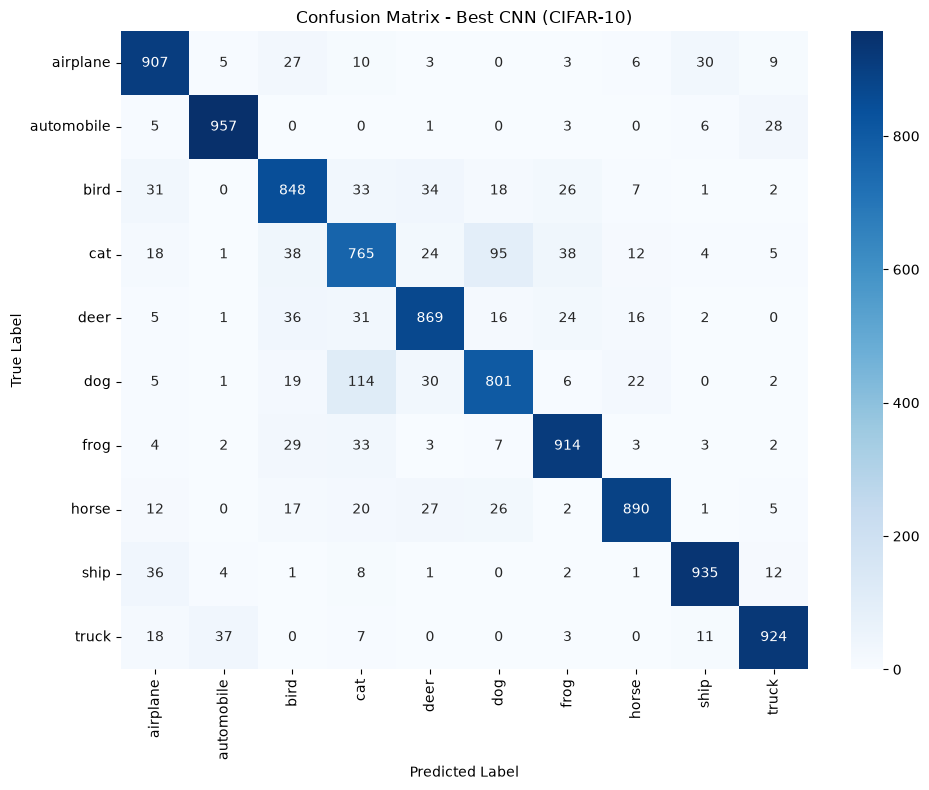

In [26]:
cm = confusion_matrix(
    all_test_labels,
    all_test_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Best CNN (CIFAR-10)")
plt.tight_layout()
plt.show()